## Install packages

In [1]:
!pip install -q datasets torchmetrics huggingface_hub timm einops

## Importing Dependencies

In [2]:
import sys
import os
import random
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
from pathlib import Path
from PIL import Image
from torchvision import transforms
from datasets import load_dataset
from torch.utils.data import Dataset, DataLoader
from torchmetrics.classification import BinaryJaccardIndex, BinaryF1Score, BinaryPrecision, BinaryRecall, BinaryAccuracy
from huggingface_hub import HfApi, login
from kaggle_secrets import UserSecretsClient

In [3]:
os.chdir('/kaggle/working')

if not os.path.exists('/kaggle/working/Tiny_model_4_CD'):
    !cd /kaggle/working && git clone https://github.com/AndreaCodegoni/Tiny_model_4_CD.git

Cloning into 'Tiny_model_4_CD'...
remote: Enumerating objects: 154, done.
remote: Counting objects: 100% (57/57), done.
remote: Compressing objects: 100% (25/25), done.
remote: Total 154 (delta 46), reused 33 (delta 32), pack-reused 97 (from 1)
Receiving objects: 100% (154/154), 6.91 MiB | 11.43 MiB/s, done.
Resolving deltas: 100% (78/78), done.


In [4]:
# Import the model
sys.path.append('/kaggle/working/Tiny_model_4_CD')
from models.change_classifier import ChangeClassifier

## Environment Setup

In [5]:
# --- LEVIR-CD STREAMING ---
print("Initializing LEVIR-CD Streaming...")
levir_train = load_dataset("ericyu/LEVIRCD_Cropped_256", split="train", streaming=True)
levir_val = load_dataset("ericyu/LEVIRCD_Cropped_256", split="validation", streaming=True)

# Transforms for LEVIR-CD to match the WHU-CD normalization
img_tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
mask_tf = transforms.ToTensor()

# --- WHU-CD PATHS ---
TRAIN_A = '/kaggle/input/datasets/mdrifaturrahman33/whu-cd-datasetunmodified-from-website/Building change detection dataset_add/1. The two-period image data/2012/splited_images/train/image'
TRAIN_B = '/kaggle/input/datasets/mdrifaturrahman33/whu-cd-datasetunmodified-from-website/Building change detection dataset_add/1. The two-period image data/2016/splited_images/train/image'
TRAIN_LABEL = '/kaggle/input/datasets/mdrifaturrahman33/whu-cd-datasetunmodified-from-website/Building change detection dataset_add/1. The two-period image data/2012/splited_images/train/label'
TEST_A = '/kaggle/input/datasets/mdrifaturrahman33/whu-cd-datasetunmodified-from-website/Building change detection dataset_add/1. The two-period image data/2012/splited_images/test/image'
TEST_B = '/kaggle/input/datasets/mdrifaturrahman33/whu-cd-datasetunmodified-from-website/Building change detection dataset_add/1. The two-period image data/2016/splited_images/test/image'
TEST_LABEL = '/kaggle/input/datasets/mdrifaturrahman33/whu-cd-datasetunmodified-from-website/Building change detection dataset_add/1. The two-period image data/2012/splited_images/test/label'

# --- WHU-CD DATASET CLASS ---
EXTS = ('.png', '.jpg', '.jpeg', '.tif', '.bmp')

Initializing LEVIR-CD Streaming...


README.md:   0%|          | 0.00/573 [00:00<?, ?B/s]

## WHU-CD Dataset

In [6]:
class WHUDataset(Dataset):
    def __init__(self, a_dir, b_dir, lbl_dir, size=256, aug=False):
        a_files   = {Path(f).stem: f for f in os.listdir(a_dir)   if f.lower().endswith(EXTS)}
        b_files   = {Path(f).stem: f for f in os.listdir(b_dir)   if f.lower().endswith(EXTS)}
        lbl_files = {Path(f).stem: f for f in os.listdir(lbl_dir) if f.lower().endswith(EXTS)}

        common = sorted(set(a_files) & set(b_files) & set(lbl_files))
        self.pairs = [
            (os.path.join(a_dir,   a_files[s]),
             os.path.join(b_dir,   b_files[s]),
             os.path.join(lbl_dir, lbl_files[s]))
            for s in common
        ]
        
        self.aug  = aug
        self.size = size
        self.img_tf = transforms.Compose([
            transforms.Resize((size, size)),
            transforms.ToTensor(),
            transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
        ])

    def __len__(self): return len(self.pairs)

    def __getitem__(self, idx):
        pa, pb, pl = self.pairs[idx]
        a = Image.open(pa).convert('RGB')
        b = Image.open(pb).convert('RGB')
        l = Image.open(pl).convert('L')

        if self.aug:
            if random.random() > 0.5:
                a,b,l = [x.transpose(Image.FLIP_LEFT_RIGHT)  for x in [a,b,l]]
            if random.random() > 0.5:
                a,b,l = [x.transpose(Image.FLIP_TOP_BOTTOM)  for x in [a,b,l]]
            ang = random.choice([0, 90, 180, 270])
            if ang: a,b,l = [x.rotate(ang) for x in [a,b,l]]

        a = self.img_tf(a)
        b = self.img_tf(b)
        l = transforms.Resize((self.size, self.size), interpolation=Image.NEAREST)(l)
        l = (transforms.ToTensor()(l) > 0.5).float()
        return a, b, l

print("Initializing WHU-CD Dataloaders...")

whu_train_dataset = WHUDataset(TRAIN_A, TRAIN_B, TRAIN_LABEL, size=256, aug=True)
whu_loader = DataLoader(whu_train_dataset, batch_size=1, shuffle=True, num_workers=2)

print("Dual-Dataset Environment Ready.")

Initializing WHU-CD Dataloaders...
Dual-Dataset Environment Ready.


--- LEVIR-CD Dataset Verification ---
Image A Shape: torch.Size([3, 256, 256]) | Type: torch.float32 | Min: -2.12, Max: 2.64
Image B Shape: torch.Size([3, 256, 256]) | Type: torch.float32 | Min: -2.12, Max: 2.64
Label Shape:   torch.Size([1, 256, 256]) | Type: torch.float32 | Min: 0.00, Max: 1.00
Label Unique Values: [0.0, 1.0]



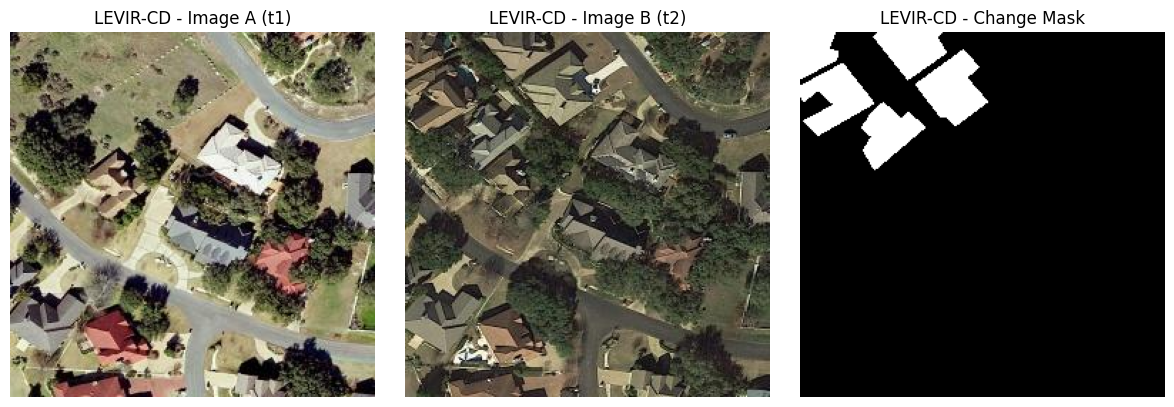

--- WHU-CD Dataset Verification ---
Image A Shape: torch.Size([3, 256, 256]) | Type: torch.float32 | Min: -1.62, Max: 2.03
Image B Shape: torch.Size([3, 256, 256]) | Type: torch.float32 | Min: -1.71, Max: 2.41
Label Shape:   torch.Size([1, 256, 256]) | Type: torch.float32 | Min: 0.00, Max: 1.00
Label Unique Values: [0.0, 1.0]



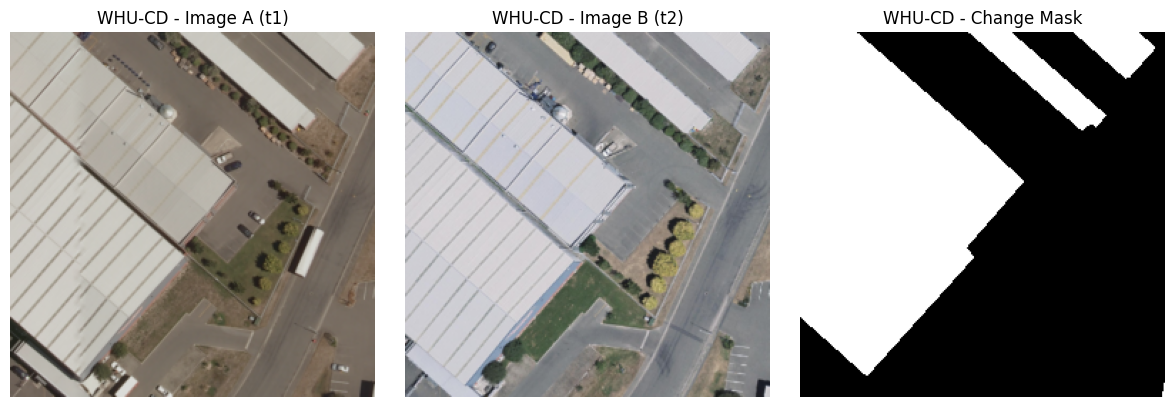

In [7]:
import matplotlib.pyplot as plt
import numpy as np

def denormalize(tensor):
    """Reverts the ImageNet normalization for visualization."""
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    # Convert CHW to HWC
    img = tensor.permute(1, 2, 0).cpu().numpy()
    img = std * img + mean
    return np.clip(img, 0, 1)

def verify_and_plot(name, img1, img2, label):
    print(f"--- {name} Dataset Verification ---")
    print(f"Image A Shape: {img1.shape} | Type: {img1.dtype} | Min: {img1.min():.2f}, Max: {img1.max():.2f}")
    print(f"Image B Shape: {img2.shape} | Type: {img2.dtype} | Min: {img2.min():.2f}, Max: {img2.max():.2f}")
    print(f"Label Shape:   {label.shape} | Type: {label.dtype} | Min: {label.min():.2f}, Max: {label.max():.2f}")
    
    # Check if label is strictly binary
    unique_vals = torch.unique(label)
    print(f"Label Unique Values: {unique_vals.tolist()}\n")

    # Plotting
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    axes[0].imshow(denormalize(img1.squeeze(0) if img1.dim() == 4 else img1))
    axes[0].set_title(f"{name} - Image A (t1)")
    axes[0].axis("off")
    
    axes[1].imshow(denormalize(img2.squeeze(0) if img2.dim() == 4 else img2))
    axes[1].set_title(f"{name} - Image B (t2)")
    axes[1].axis("off")
    
    axes[2].imshow(label.squeeze().cpu().numpy(), cmap='gray')
    axes[2].set_title(f"{name} - Change Mask")
    axes[2].axis("off")
    
    plt.tight_layout()
    plt.show()

# Verify LEVIR-CD
try:
    levir_batch = next(iter(levir_train))
    l_img1 = img_tf(levir_batch['imageA'])
    l_img2 = img_tf(levir_batch['imageB'])
    l_label = (mask_tf(levir_batch['label']) > 0.5).float()
    verify_and_plot("LEVIR-CD", l_img1, l_img2, l_label)
except Exception as e:
    print(f"Error loading LEVIR-CD: {e}")

# Verify WHU-CD
try:
    # whu_loader returns batched data [B, C, H, W]
    w_img1, w_img2, w_label = next(iter(whu_loader))
    # Extract the first item in the batch
    verify_and_plot("WHU-CD", w_img1[0], w_img2[0], w_label[0])
except Exception as e:
    print(f"Error loading WHU-CD: {e}")

## Training

In [8]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Initialize Official TinyCD
model = ChangeClassifier(
    bkbn_name="efficientnet_b4", 
    pretrained=True
).to(device)

optimizer = optim.AdamW(model.parameters(), lr=0.0035, weight_decay=0.01)
criterion = nn.BCEWithLogitsLoss()
iou_metric = BinaryJaccardIndex().to(device)
f1_metric = BinaryF1Score().to(device)

epochs = 4
steps_per_epoch = 1500  # 750 LEVIR + 750 WHU
batch_size = 8

os.makedirs("/kaggle/working/cd_weights", exist_ok=True)
best_iou = 0.0

print(f"Starting Fused Change Detection Training on {device}...")

for epoch in range(epochs):
    model.train()
    
    levir_iter = iter(levir_train)
    whu_iter = iter(whu_loader)
    
    optimizer.zero_grad()
    accumulated_loss = 0
    
    for step in range(steps_per_epoch):
        is_levir_step = (step % 2 == 0)
        
        try:
            if is_levir_step:
                batch = next(levir_iter)
                img1 = img_tf(batch['imageA']).unsqueeze(0).to(device)
                img2 = img_tf(batch['imageB']).unsqueeze(0).to(device)
                label = (mask_tf(batch['label']).unsqueeze(0) > 0.5).float().to(device)
            else:
                img_a, img_b, lbl = next(whu_iter)
                img1 = img_a.to(device)
                img2 = img_b.to(device)
                label = lbl.to(device)
        except StopIteration:
            break
            
        # FIX: Pass img1 and img2 as separate arguments
        outputs = model(img1, img2)
        
        # TinyCD returns a single tensor directly, but this safeguard works fine
        main_output = outputs[0] if isinstance(outputs, (list, tuple)) else outputs
        
        loss = criterion(main_output, label) / batch_size
        loss.backward()
        accumulated_loss += loss.item()
        
        if (step + 1) % batch_size == 0:
            optimizer.step()
            optimizer.zero_grad()
            
            if (step + 1) % 200 == 0:
                print(f"Epoch [{epoch+1}/{epochs}] Step [{step+1}/{steps_per_epoch}] Loss: {accumulated_loss:.4f}")
            accumulated_loss = 0
            
    # Quick Evaluation to save best weights
    model.eval()
    val_iter = iter(levir_val)
    val_iou = 0
    val_steps = 100 
    
    with torch.no_grad():
        for v_step in range(val_steps):
            try:
                v_batch = next(val_iter)
                v_img1 = img_tf(v_batch['imageA']).unsqueeze(0).to(device)
                v_img2 = img_tf(v_batch['imageB']).unsqueeze(0).to(device)
                v_label = (mask_tf(v_batch['label']).unsqueeze(0) > 0.5).float().to(device)
                
                # FIX: Pass v_img1 and v_img2 as separate arguments
                v_outputs = model(v_img1, v_img2)
                v_main = v_outputs[0] if isinstance(v_outputs, (list, tuple)) else v_outputs
                
                preds = (torch.sigmoid(v_main) > 0.5).float()
                val_iou += iou_metric(preds, v_label).item()
            except StopIteration:
                val_steps = v_step
                break
                
    avg_iou = val_iou / val_steps
    print(f"Epoch {epoch+1} Checkpoint | Val IoU: {avg_iou:.4f}")
    
    if avg_iou > best_iou:
        best_iou = avg_iou
        torch.save(model.state_dict(), "/kaggle/working/cd_weights/best_tinycd_fusion.pth")
        print("✅ New best dual-dataset model saved.")

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=EfficientNet_B4_Weights.IMAGENET1K_V1`. You can also use `weights=EfficientNet_B4_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/efficientnet_b4_rwightman-23ab8bcd.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b4_rwightman-23ab8bcd.pth


100%|██████████| 74.5M/74.5M [00:00<00:00, 218MB/s]


Starting Fused Change Detection Training on cuda...
Epoch [1/4] Step [200/1500] Loss: 0.7334
Epoch [1/4] Step [400/1500] Loss: 0.6947
Epoch [1/4] Step [600/1500] Loss: 0.6933
Epoch [1/4] Step [800/1500] Loss: 0.6926
Epoch [1/4] Step [1000/1500] Loss: 0.6926
Epoch [1/4] Step [1200/1500] Loss: 0.6831
Epoch [1/4] Step [1400/1500] Loss: 0.6959
Epoch 1 Checkpoint | Val IoU: 0.0479
✅ New best dual-dataset model saved.
Epoch [2/4] Step [200/1500] Loss: 0.6682
Epoch [2/4] Step [400/1500] Loss: 0.6502
Epoch [2/4] Step [600/1500] Loss: 0.6868
Epoch [2/4] Step [800/1500] Loss: 0.6740
Epoch [2/4] Step [1000/1500] Loss: 0.6778
Epoch [2/4] Step [1200/1500] Loss: 0.6682
Epoch [2/4] Step [1400/1500] Loss: 0.6786
Epoch 2 Checkpoint | Val IoU: 0.0489
✅ New best dual-dataset model saved.
Epoch [3/4] Step [200/1500] Loss: 0.6877
Epoch [3/4] Step [400/1500] Loss: 0.6614
Epoch [3/4] Step [600/1500] Loss: 0.6750
Epoch [3/4] Step [800/1500] Loss: 0.6762
Epoch [3/4] Step [1000/1500] Loss: 0.6729
Epoch [3/4] St

## Evaluation

In [9]:
print("\n--- RUNNING FINAL EVALUATION ---")

model.load_state_dict(torch.load("/kaggle/working/cd_weights/best_tinycd_fusion.pth"))
model.eval()

# Initialize Metrics Collection
metrics = {
    'levir': {'iou': BinaryJaccardIndex().to(device), 'f1': BinaryF1Score().to(device), 'precision': BinaryPrecision().to(device), 'recall': BinaryRecall().to(device), 'accuracy': BinaryAccuracy().to(device)},
    'whu': {'iou': BinaryJaccardIndex().to(device), 'f1': BinaryF1Score().to(device), 'precision': BinaryPrecision().to(device), 'recall': BinaryRecall().to(device), 'accuracy': BinaryAccuracy().to(device)}
}

levir_val_iter = iter(load_dataset("ericyu/LEVIRCD_Cropped_256", split="validation", streaming=True))
whu_test_dataset = WHUDataset(TEST_A, TEST_B, TEST_LABEL, size=256, aug=False)
whu_test_loader = iter(DataLoader(whu_test_dataset, batch_size=1, shuffle=False))

eval_steps = 300 

with torch.no_grad():
    for step in range(eval_steps):
        try:
            batch_l = next(levir_val_iter)
            img1_l, img2_l = img_tf(batch_l['imageA']).unsqueeze(0).to(device), img_tf(batch_l['imageB']).unsqueeze(0).to(device)
            label_l = (mask_tf(batch_l['label']).unsqueeze(0) > 0.5).float().to(device)
            
            # FIX: Passed as separate arguments
            out_l = model(img1_l, img2_l)
            main_l = out_l[0] if isinstance(out_l, (list, tuple)) else out_l
            preds_l = (torch.sigmoid(main_l) > 0.5).float()
            for metric in metrics['levir'].values(): metric.update(preds_l, label_l)
        except StopIteration: pass

        try:
            img1_w, img2_w, label_w = next(whu_test_loader)
            img1_w, img2_w, label_w = img1_w.to(device), img2_w.to(device), label_w.to(device)
            
            # FIX: Passed as separate arguments
            out_w = model(img1_w, img2_w)
            main_w = out_w[0] if isinstance(out_w, (list, tuple)) else out_w
            preds_w = (torch.sigmoid(main_w) > 0.5).float()
            for metric in metrics['whu'].values(): metric.update(preds_w, label_w)
        except StopIteration: pass

print("\n" + "="*50)
print(f"{'METRIC':<20} | {'LEVIR-CD':<12} | {'WHU-CD':<12}")
print("="*50)

for m_key, display in [('accuracy', 'Overall Accuracy'), ('iou', 'IoU (Jaccard)'), ('f1', 'F1-Score'), ('precision', 'Precision'), ('recall', 'Recall')]:
    l_score = metrics['levir'][m_key].compute().item() * 100
    w_score = metrics['whu'][m_key].compute().item() * 100
    print(f"{display:<20} | {l_score:>9.2f}%  | {w_score:>9.2f}%")
print("="*50)


--- RUNNING FINAL EVALUATION ---

METRIC               | LEVIR-CD     | WHU-CD      
Overall Accuracy     |     27.34%  |     45.55%
IoU (Jaccard)        |      6.58%  |     26.60%
F1-Score             |     12.36%  |     42.03%
Precision            |      6.67%  |     26.87%
Recall               |     84.51%  |     96.34%


## Huggingface Export

In [10]:
try:
    user_secrets = UserSecretsClient()
    hf_token = user_secrets.get_secret("HF_TOKEN")
    login(token=hf_token)
except Exception as e:
    print("Authentication failed. Add 'HF_TOKEN' to Kaggle Secrets.")
    raise e

repo_id = "nillohitroy/satquery-tinycd-fused"
api = HfApi()

print(f"Creating repository: {repo_id}...")
api.create_repo(repo_id=repo_id, repo_type="model", exist_ok=True)

print("Uploading best_tinycd_fusion.pth...")
api.upload_file(
    path_or_fileobj="/kaggle/working/cd_weights/best_tinycd_fusion.pth",
    path_in_repo="best_tinycd.pth",
    repo_id=repo_id,
    repo_type="model"
)

print(f"Upload complete! Weights are live at: https://huggingface.co/{repo_id}")

Creating repository: nillohitroy/satquery-tinycd-fused...
Uploading best_tinycd_fusion.pth...


Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

Upload complete! Weights are live at: https://huggingface.co/nillohitroy/satquery-tinycd-fused
